In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.tree import DecisionTreeClassifier

# 1. Inisialisasi Path relatif ke folder data/processed 
PROCESSED_DIR = Path("../data/processed")
if not PROCESSED_DIR.exists():
  PROCESSED_DIR = Path("data/processed")

# 2. Load Dataset Train & Validation
X_train = pd.read_csv(PROCESSED_DIR / "X_train.csv")
y_train = pd.read_csv(PROCESSED_DIR / "y_train.csv").values.ravel()

X_val = pd.read_csv(PROCESSED_DIR / "X_val.csv")
y_val = pd.read_csv(PROCESSED_DIR / "y_val.csv").values.ravel()

# 3. Load Class Weights JSON
with open(PROCESSED_DIR / "class_weights.json", "r") as f:
  class_weights_raw = json.load(f)

# Mapping Kunci JSON ke Integer (0, 1, 2, 3)
label_mapping = {"Low": 0, "Moderate": 1, "High": 2, "Extreme": 3}

class_weights = {}
for k, v in class_weights_raw.items():
  if k in label_mapping:
    class_weights[label_mapping[k]] = float(v)
  else:
    class_weights[int(k)] = float(v)

print(f"Data Training   : {X_train.shape[0]} sampel, {X_train.shape[1]} fitur")
print(f"Data Validation : {X_val.shape[0]} sampel, {X_val.shape[1]} fitur")
print(f"Class Weights   : {class_weights}")

Data Training   : 10206 sampel, 32 fitur
Data Validation : 2555 sampel, 32 fitur
Class Weights   : {0: 4.361538461538461, 1: 0.7906724511930586, 2: 0.4879518072289157, 3: 2.190128755364807}


In [8]:
# Instansiasi & Pelatihan Model Baseline Decision Tree
baseline_model = DecisionTreeClassifier(
    criterion="gini", max_depth=None, random_state=42, class_weight=class_weights
)

# Fitting Model HANYA pada Data Training
try:
  baseline_model.fit(X_train, y_train)
  print("Status: Model Baseline Decision Tree Berhasil Dilatih!")

except Exception as e:
  print(f"Status: Pelatihan Model GAGAL!")
  print(f"Penyebab Error: {e}")

Status: Model Baseline Decision Tree Berhasil Dilatih!


In [3]:
import time
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)

# 1. Ukur Waktu Pelatihan & Inferensi
start_train = time.time()
baseline_model.fit(X_train, y_train)
end_train = time.time()

start_infer = time.time()
y_pred_val = baseline_model.predict(X_val)
end_infer = time.time()

train_duration = end_train - start_train
infer_duration = end_infer - start_infer
latency_per_sample = (infer_duration / len(X_val)) * 1000

# 2. Hitung Metrik Train & Validation
y_pred_train = baseline_model.predict(X_train)
acc_train = accuracy_score(y_train, y_pred_train)
macro_f1_train = f1_score(y_train, y_pred_train, average="macro")

acc_val = accuracy_score(y_val, y_pred_val)
macro_f1_val = f1_score(y_val, y_pred_val, average="macro")
weighted_f1_val = f1_score(y_val, y_pred_val, average="weighted")

# 3. Hitung Status Overfitting Dinamis
gap = abs(macro_f1_train - macro_f1_val)
if gap >= 0.20:
  status_overfit = "Mengalami Overfitting Parah"
elif gap >= 0.10:
  status_overfit = "Mengalami Overfitting Moderat"
else:
  status_overfit = "Model Stabil (Good Fit)"

# 4. Tampilkan Hasil
print("=" * 60)
print("ANALISIS LENGKAP BASELINE MODEL — DECISION TREE")
print("=" * 60)
print(f"Validation Accuracy      : {acc_val:.4f} ({acc_val*100:.2f}%)")
print(f"Validation Macro F1      : {macro_f1_val:.4f}")
print(f"Validation Weighted F1   : {weighted_f1_val:.4f}")
print("-" * 60)
print(
    f"Training Macro F1        : {macro_f1_train:.4f} (Accuracy: {acc_train*100:.2f}%)"
)
print(f"Train-Val Gap (Overfit)  : {gap:.4f} ({status_overfit})")
print(f"Waktu Training           : {train_duration:.4f} detik")
print(
    f"Waktu Inferensi Total    : {infer_duration:.4f} detik ({latency_per_sample:.4f} ms/sample)"
)
print("-" * 60)
print("\nClassification Report (Validation Set 2025):\n")
target_names = [
    "Class 0 (Low)",
    "Class 1 (Moderate)",
    "Class 2 (High)",
    "Class 3 (Extreme)",
]
print(classification_report(y_val, y_pred_val, target_names=target_names))

ANALISIS LENGKAP BASELINE MODEL — DECISION TREE
Validation Accuracy      : 0.5033 (50.33%)
Validation Macro F1      : 0.3679
Validation Weighted F1   : 0.5021
------------------------------------------------------------
Training Macro F1        : 1.0000 (Accuracy: 100.00%)
Train-Val Gap (Overfit)  : 0.6321 (Mengalami Overfitting Parah)
Waktu Training           : 0.1780 detik
Waktu Inferensi Total    : 0.0016 detik (0.0006 ms/sample)
------------------------------------------------------------

Classification Report (Validation Set 2025):

                    precision    recall  f1-score   support

     Class 0 (Low)       0.17      0.15      0.16       117
Class 1 (Moderate)       0.42      0.42      0.42       750
    Class 2 (High)       0.61      0.62      0.62      1425
 Class 3 (Extreme)       0.28      0.29      0.28       263

          accuracy                           0.50      2555
         macro avg       0.37      0.37      0.37      2555
      weighted avg       0.50    

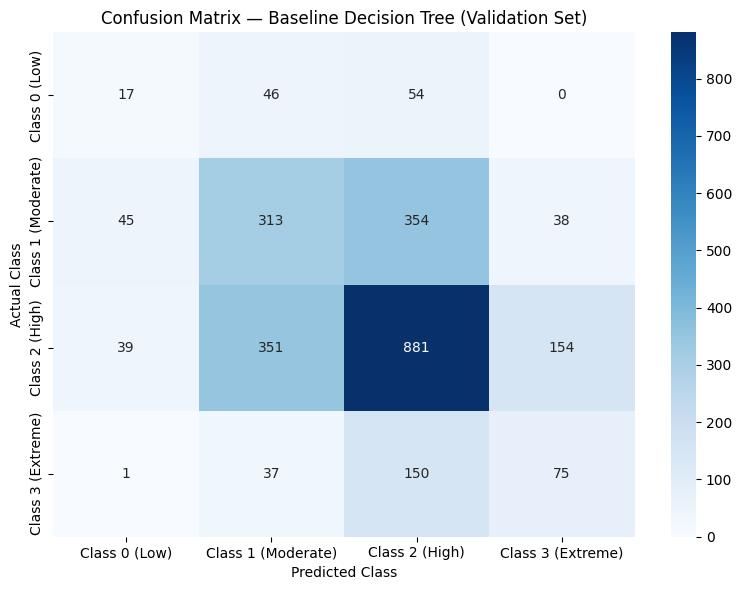

In [4]:
# Visualisasi Heatmap Confusion Matrix
cm = confusion_matrix(y_val, y_pred_val)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_names,
    yticklabels=target_names,
)
plt.title("Confusion Matrix — Baseline Decision Tree (Validation Set)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()